# Notebook 13 — Collect All Results + Comparison Table

Run this after all classifier notebooks (01–12) have finished.
Reads each `result_*.json` file and builds the final comparison table.

In [1]:
import os, warnings, pickle, copy, json
import numpy as np
import pandas as pd
from pathlib import Path

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score)

warnings.filterwarnings("ignore")
np.random.seed(42)

DATASET_ROOT = "/home/ali/Desktop/Algerian_Lamiaceae_v3"
OUTPUT_DIR   = os.path.join(DATASET_ROOT, "results")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Output: {OUTPUT_DIR}")


Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Output: /home/ali/Desktop/Algerian_Lamiaceae_v3/results


In [2]:
import glob, matplotlib.pyplot as plt, seaborn as sns

# ── Load all result JSON files ────────────────────────────────────────────────
result_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "result_*.json")))
print(f"Found {len(result_files)} result files:")
for f in result_files:
    print(f"  {os.path.basename(f)}")

results = []
for f in result_files:
    with open(f) as fp:
        results.append(json.load(fp))

results_df = pd.DataFrame(results)[
    ["Classifier","Accuracy","Precision","Recall","F1","AUC"]
].sort_values("F1", ascending=False).reset_index(drop=True)

print("\n" + "="*72)
print("TABLE 1 — Classifier Comparison")
print("="*72)
print(results_df.to_string(index=False))

best_row  = results_df.iloc[0]
best_name = best_row["Classifier"]
best_f1   = best_row["F1"]
print(f"\nBest classifier : {best_name}")
print(f"Best F1         : {best_f1}%")

results_df.to_csv(os.path.join(OUTPUT_DIR,"results_classifiers.csv"),index=False)
print(f"\nSaved to {OUTPUT_DIR}/results_classifiers.csv")


Found 25 result files:
  result_AdaBoost.json
  result_AdaBoost_Optuna.json
  result_CatBoost.json
  result_CatBoost_Optuna.json
  result_Decision_Tree.json
  result_Decision_Tree_Optuna.json
  result_EfficientNetB3_CNN.json
  result_KNN.json
  result_KNN_Optuna.json
  result_LDA.json
  result_LDA_Optuna.json
  result_LightGBM.json
  result_LightGBM_Optuna.json
  result_Logistic_Regression.json
  result_Logistic_Regression_Optuna.json
  result_MLP.json
  result_MLP_Optuna.json
  result_Naive_Bayes.json
  result_Naive_Bayes_Optuna.json
  result_QDA.json
  result_QDA_Optuna.json
  result_Random_Forest.json
  result_Random_Forest_Optuna.json
  result_SVM_LinearSVC.json
  result_SVM_LinearSVC_Optuna.json

TABLE 1 — Classifier Comparison
                Classifier  Accuracy  Precision  Recall    F1   AUC
        EfficientNetB3_CNN     93.66      90.55   94.88 92.52   NaN
                MLP_Optuna     91.80      91.99   91.80 91.88 99.13
             SVM_LinearSVC     91.46      91.76   91.

                  Classifier  Accuracy  Precision  Recall    F1
        EfficientNetB3 (CNN)     93.66      94.00   93.66 93.73
                MLP (Optuna)     91.80      91.99   91.80 91.88
           LightGBM (Optuna)     91.38      91.56   91.38 91.45
Logistic Regression (Optuna)     91.12      91.42   91.12 91.24
      SVM LinearSVC (Optuna)     91.04      91.36   91.04 91.16
      Random Forest (Optuna)     90.57      90.87   90.57 90.67
           CatBoost (Optuna)     90.24      90.60   90.24 90.36
                LDA (Optuna)     89.64      90.37   89.64 89.88
                QDA (Optuna)     89.56      90.43   89.56 89.87
                KNN (Optuna)     87.66      89.30   87.66 88.08
           AdaBoost (Optuna)     82.80      84.57   82.80 83.47
      Decision Tree (Optuna)     77.35      81.06   77.35 78.60
        Naive Bayes (Optuna)     69.61      84.05   69.61 73.94


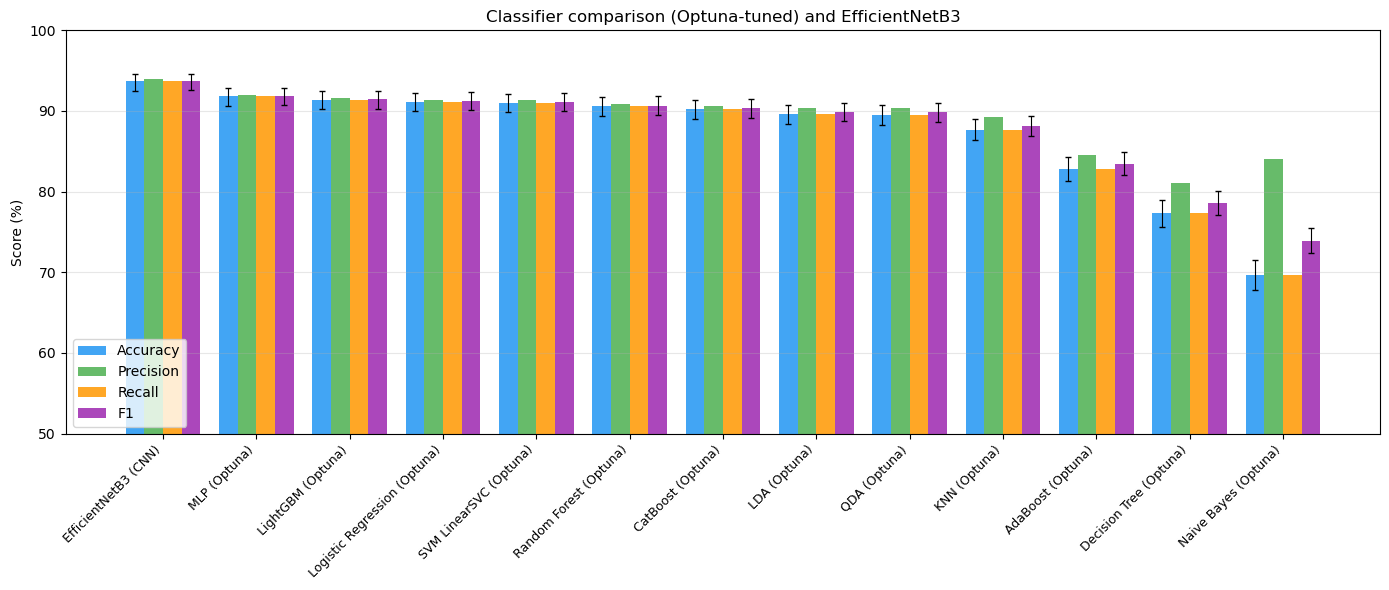

Chart saved.


In [3]:
# ── Bar chart: the 12 Optuna-tuned classifiers (as in Table 8) + EfficientNetB3 ──
rows = []
for r in results:
    name = r["Classifier"]
    if not name.endswith("_Optuna"):
        continue                                   # defaults are discussed in the text only
    ci = r.get("Bootstrap_CI_95", {})
    rows.append({"Classifier": name.replace("_Optuna", "").replace("_", " ") + " (Optuna)",
                 "Accuracy": r["Accuracy"], "Precision": r["Precision"],
                 "Recall": r["Recall"], "F1": r["F1"],
                 "Acc_lo": ci["Accuracy"]["ci_lo"], "Acc_hi": ci["Accuracy"]["ci_hi"],
                 "F1_lo": ci["F1"]["ci_lo"], "F1_hi": ci["F1"]["ci_hi"]})

# EfficientNetB3: WEIGHTED averages so it is comparable with the classifiers
# (result_EfficientNetB3_CNN.json stores macro values; weighted values from Notebook 14 report)
rows.append({"Classifier": "EfficientNetB3 (CNN)",
             "Accuracy": 93.66, "Precision": 94.00, "Recall": 93.66, "F1": 93.73,
             "Acc_lo": 92.5, "Acc_hi": 94.6, "F1_lo": 92.6, "F1_hi": 94.6})

plot_df = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
print(plot_df[["Classifier", "Accuracy", "Precision", "Recall", "F1"]].to_string(index=False))
assert len(plot_df) == 13, f"expected 12 tuned classifiers + CNN, got {len(plot_df)}"

fig, ax = plt.subplots(figsize=(14, 6))
x, w = np.arange(len(plot_df)), 0.2
for i, (metric, color) in enumerate(zip(["Accuracy", "Precision", "Recall", "F1"],
                                        ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0"])):
    yerr = None
    if metric == "Accuracy":
        yerr = [plot_df.Accuracy - plot_df.Acc_lo, plot_df.Acc_hi - plot_df.Accuracy]
    elif metric == "F1":
        yerr = [plot_df.F1 - plot_df.F1_lo, plot_df.F1_hi - plot_df.F1]
    ax.bar(x + i*w, plot_df[metric], w, label=metric, color=color, alpha=0.85,
           yerr=yerr, capsize=2, error_kw={"elinewidth": 0.8})
ax.set_xticks(x + 1.5*w)
ax.set_xticklabels(plot_df["Classifier"], rotation=45, ha="right", fontsize=9)
ax.set(ylabel="Score (%)", ylim=(50, 100),
       title="Classifier comparison (Optuna-tuned) and EfficientNetB3")
ax.legend(loc="lower left"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "classifier_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()
print("Chart saved.")

In [4]:
# ── Load best model for downstream tasks ─────────────────────────────────────
best_safe = best_name.replace(" ","_").replace("(","").replace(")","")
model_path = os.path.join(OUTPUT_DIR, f"model_{best_safe}.pkl")

if os.path.exists(model_path):
    with open(model_path,"rb") as f:
        best_obj = pickle.load(f)
    print(f"Best model loaded: {model_path}")
else:
    print(f"Model file not found: {model_path}")
    print("Run the corresponding classifier notebook first.")


Model file not found: /home/ali/Desktop/Algerian_Lamiaceae_v3/results/model_EfficientNetB3_CNN.pkl
Run the corresponding classifier notebook first.
